# **Week 6 Lab** <br/> Practical SIFT Application
## Task 3 (SIFT_Matching.ipynb)
1. Upload  a pair of images (Leftpart & Rightpart) in Jupyter-Lab or in the current folder. In the code (SIFT_Matching.ipynb), ensure proper naming of Left and Right Images

    ```python
    train_img = cv2.imread('Leftpart.jpg')
    query_img = cv2.imread('Rightpart.jpg')
    ```
2. Run/Execute the program, view output results, observe and comment on the detected keypoints matched.


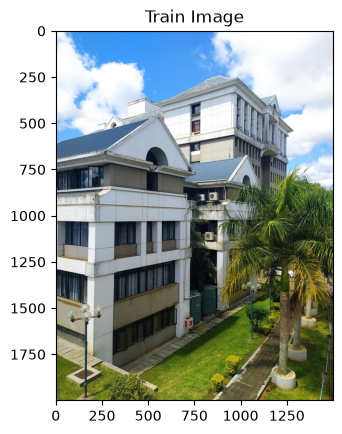

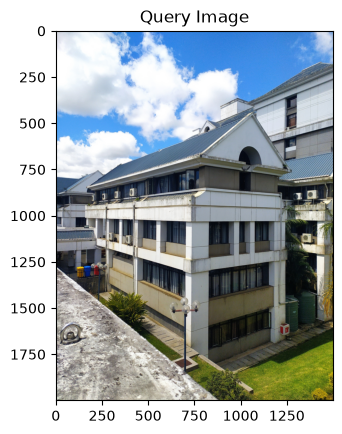

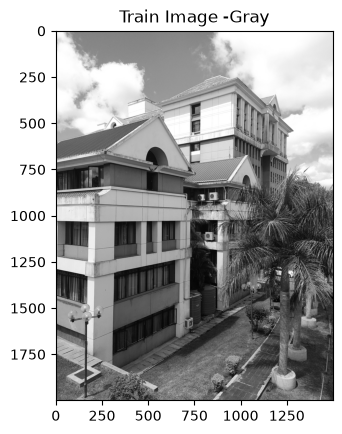

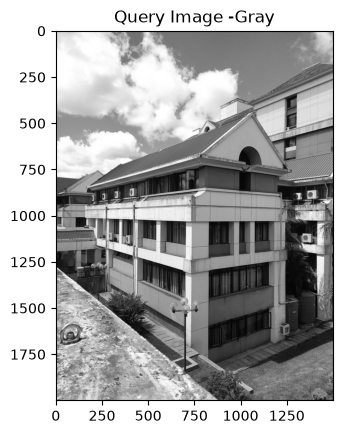

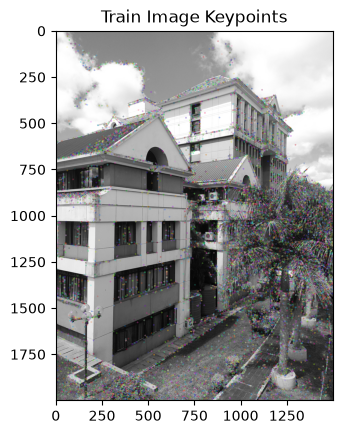

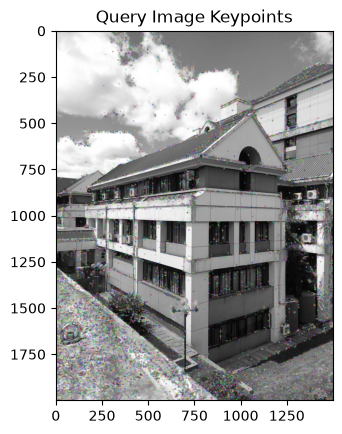

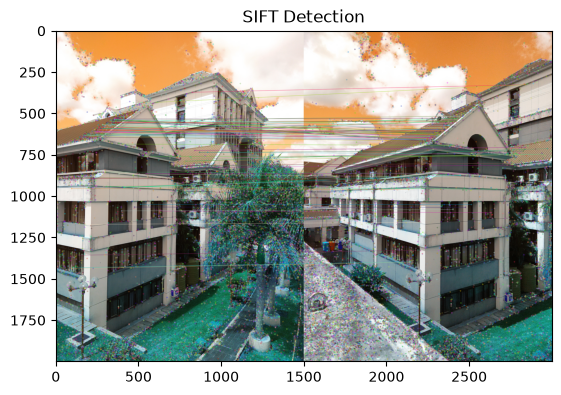

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


#Right Image
train_img = cv2.imread('Images/BridgeRight2.jpg')

#Left Image
query_img = cv2.imread('Images/BridgeLeft2.jpg')

# Show Images 
plt.figure(1)
plt.imshow(cv2.cvtColor(train_img, cv2.CV_32S))
plt.title('Train Image')

plt.figure(2)
plt.imshow(cv2.cvtColor(query_img, cv2.CV_32S))
plt.title('Query Image')

# Turn Images to grayscale

def to_gray(color_img):
    gray = cv2.cvtColor(color_img, cv2.COLOR_BGR2GRAY)
    return gray

train_img_gray = to_gray(train_img)
query_img_gray = to_gray(query_img)

plt.figure(3)
plt.imshow(train_img_gray, cmap='gray')
plt.title('Train Image -Gray')


plt.figure(4)
plt.imshow(query_img_gray, cmap= 'gray')
plt.title('Query Image -Gray')


# Initialise SIFT detector
sift = cv2.SIFT_create()
    
# Generate SIFT keypoints and descriptors
train_kp, train_desc = sift.detectAndCompute(train_img_gray, None)
query_kp, query_desc = sift.detectAndCompute(query_img_gray, None)

plt.figure(5)
plt.imshow((cv2.drawKeypoints(train_img_gray, train_kp, train_img.copy())))
plt.title('Train Image Keypoints')

plt.figure(6)
plt.imshow((cv2.drawKeypoints(query_img_gray, query_kp, query_img.copy())))
plt.title('Query Image Keypoints')


# create a BFMatcher object which will match up the SIFT features
bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=True)

matches = bf.match(train_desc, query_desc)

# Sort the matches in the order of their distance.
matches = sorted(matches, key = lambda x:x.distance)

# draw the top N matches
N_MATCHES = 100

match_img = cv2.drawMatches(
    train_img, train_kp,
    query_img, query_kp,
    matches[:N_MATCHES], query_img.copy(), flags=0)

plt.figure(7)
plt.imshow(match_img)
plt.title('SIFT Detection')
plt.show()

### Comments
1. TowerLeft.jpg & TowerRight.jpg
    > The output confirms that SIFT is robust to scale and viewpoint changes because the building appears in both images with similar geometry, even though the camera viewpoint is slightly different. Most of the matched points are concentrated on the repeated window patterns and edges of the structure, which are highly distinctive. This is why the matching lines are dense and visually concentrated on the tower rather than in the sky or the ground.

    > A few mismatches are still possible because repetitive patterns like windows can look similar in different areas, but the overall result is strong. In short, the experiment demonstrates that SIFT can reliably find correspondences between two related images and is well suited for image registration and matching in this scene.

2. CafetariaLeft.png & CafetariaRight.png
    > The output shows a strong SIFT match for the building facade, with many corresponding keypoints detected around the roofline, columns, windows, and architectural details. This indicates that the same structure is correctly recognized in both images, even though the viewpoint and the foreground people differ slightly. The match is not as clean as the earlier tower example because moving people and the surrounding vegetation create some local variations, but the main building features still produce reliable correspondences. The dominant repeated features are the façade, pillars, windows, and landscaping.

3. ZurichImageA.jpg & ZurichImageB.jpg
    > The result is visually convincing because the matched lines are spread across the main building and not randomly scattered. There are some mismatches and weaker matches due to differences in viewpoint, moving people, and the presence of trees and foreground objects, but the overall correspondence is still very good. The building façade, windows, roofline, and architectural edge are the most distinctive and stable features in both images.

4. BridgeRight2.jpg & BridgeLeft2.jpg
    > The matched features align across the two images in the same region of the scene rather than being scattered randomly. A few weaker or mismatched points are expected due to perspective differences, lighting, and small objects like trees or foreground details, but the overall pattern is consistent and strong.